In [ ]:
import os
import re
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import RobustScaler

# Set Kaggle API Token
os.environ['KAGGLE_API_TOKEN'] = "KGAT_cae52fa604f2700fee7662dc69ee7f2c"

# Install dependencies
!pip install -q kaggle openpyxl

print("Kaggle API configured")

Kaggle API configured


In [ ]:
# Create designated directories
!mkdir -p data/colombo_land data/islandwide_land data/property_ads data/colombo_houses

print("Downloading Dataset 1: Colombo District Land Prices...")
!kaggle datasets download -d ruchiraayeshmantha/land-prices-of-colombo-district -p data/colombo_land --unzip

print("\nDownloading Dataset 2: Land Prices in Sri Lanka...")
!kaggle datasets download -d dewminimnaadi/land-prices-in-sri-lanka -p data/islandwide_land --unzip

print("\nDownloading Dataset 3: Sri Lanka Property Ads Dataset...")
!kaggle datasets download -d ivantha/sri-lanka-property-ads-dataset -p data/property_ads --unzip

print("\nDownloading Dataset 4: Colombo House Prices Dataset...")
!kaggle datasets download -d pudamyavidusini/colombo-house-prices-dataset -p data/colombo_houses --unzip

print("\ndatasets successfully downloaded")

Dataset URL: https://www.kaggle.com/datasets/ruchiraayeshmantha/land-prices-of-colombo-district
License(s): unknown
100% 1.16M/1.16M [00:00<00:00, 43.5MB/s]


Dataset URL: https://www.kaggle.com/datasets/dewminimnaadi/land-prices-in-sri-lanka
License(s): CC0-1.0
100% 436k/436k [00:00<00:00, 17.3MB/s]


Dataset URL: https://www.kaggle.com/datasets/ivantha/sri-lanka-property-ads-dataset
License(s): ODC Attribution License (ODC-By)
100% 39.5M/39.5M [00:00<00:00, 88.8MB/s]


Dataset URL: https://www.kaggle.com/datasets/pudamyavidusini/colombo-house-prices-dataset
License(s): CC0-1.0
100% 57.8k/57.8k [00:00<00:00, 64.3MB/s]


datasets successfully downloaded


In [ ]:
# Load Colombo Land Excel dataset
df_d1_raw = pd.read_excel('data/colombo_land/Land prices of Colombo district-Sri Lanka.xlsx')

d1 = pd.DataFrame({
    'district': 'Colombo',
    'location': df_d1_raw['Address'].astype(str).str.strip().str.lower(),
    'property_type': 'Bare Land',
    'land_type': df_d1_raw['Land_type'].astype(str),
    'perches': df_d1_raw['Land_size(Perches)'].astype(float),
    'price_per_perch': df_d1_raw['Price per Perch'].astype(float),
    'dataset_source': 'colombo_land_detailed'
})

print(f"Dataset 1 Standardized: {len(d1):,d} records.")
display(d1.head(2))

Dataset 1 Standardized: 4,494 records.


,district,location,property_type,land_type,perches,price_per_perch,dataset_source
0,Colombo,battaramulla,Bare Land,"Commercial, Residential",12.0,3800000.0,colombo_land_detailed
1,Colombo,nawala,Bare Land,"Commercial, Residential",22.0,6500000.0,colombo_land_detailed


In [ ]:
# Load Island-wide CSV
df_d2_raw = pd.read_csv('data/islandwide_land/sri_lanka_land_prices.csv')

d2 = pd.DataFrame({
    'district': df_d2_raw['District'].astype(str).str.strip(),
    'location': df_d2_raw['Village'].astype(str).str.strip().str.lower(),
    'property_type': 'Bare Land',
    'land_type': df_d2_raw['Land_Type'].astype(str),
    'perches': df_d2_raw['Perches'].astype(float),
    'price_per_perch': df_d2_raw['Price_Per_Perch'].astype(float),
    'dataset_source': 'sri_lanka_islandwide'
})

print(f"Dataset 2 Standardized: {len(d2):,d} records.")
display(d2.head(2))

Dataset 2 Standardized: 20,000 records.


,district,location,property_type,land_type,perches,price_per_perch,dataset_source
0,Matale,west village,Bare Land,Mixed,65.0,2284482.0,sri_lanka_islandwide
1,Kandy,old hill,Bare Land,Mixed,70.0,807467.0,sri_lanka_islandwide


In [ ]:
# Load classifieds dataset
df_d3_raw = pd.read_csv('data/property_ads/properties.csv', low_memory=False)

# Filter specifically for Land advertisements
land_ads = df_d3_raw[df_d3_raw['category'].isin(['Land For Sale', 'Land'])].copy()

def parse_price(val):
    if pd.isna(val): return np.nan
    digits = re.sub(r'[^\d.]', '', str(val))
    try: return float(digits)
    except: return np.nan

def parse_district(val):
    try: return ast.literal_eval(val).get('name', 'Unknown')
    except: return 'Unknown'

def parse_perches(val):
    try:
        data = ast.literal_eval(val)
        size_str = str(data.get('Land size', data.get('Size', '')))
        match = re.search(r'([\d.]+)\s*(perch|acres|acre)?', size_str, re.IGNORECASE)
        if match:
            num = float(match.group(1))
            unit = str(match.group(2)).lower() if match.group(2) else 'perch'
            if 'acre' in unit:
                return num * 160.0  # 1 Acre = 160 Perches
            return num
        return np.nan
    except:
        return np.nan

d3 = pd.DataFrame({
    'district': land_ads['area'].apply(parse_district),
    'location': land_ads['location'].astype(str).str.strip().str.lower(),
    'property_type': 'Bare Land',
    'land_type': land_ads['category'].astype(str),
    'perches': land_ads['properties'].apply(parse_perches),
    'total_price': land_ads['price'].apply(parse_price),
    'dataset_source': 'ikman_property_ads'
})

# Compute price per perch and drop rows with missing values
d3['price_per_perch'] = d3['total_price'] / d3['perches']
d3 = d3.drop(columns=['total_price']).dropna(subset=['price_per_perch', 'perches'])

print(f"Dataset 3 Standardized: {len(d3):,d} valid land records extracted.")
display(d3.head(2))

Dataset 3 Standardized: 109,201 valid land records extracted.


,district,location,property_type,land_type,perches,dataset_source,price_per_perch
1,Kurunegala,kurunegala city,Bare Land,Land,15.0,ikman_property_ads,3333.333333
2,Gampaha,kelaniya,Bare Land,Land For Sale,18.5,ikman_property_ads,86486.486486


In [ ]:
# Load Colombo House Dataset
df_d4_raw = pd.read_csv('data/colombo_houses/Colombo-House-Dataset-3000.csv')

# Clean numeric prices and house sizes
house_prices = df_d4_raw['PRICE'].astype(str).str.replace(',', '').astype(float)
house_sqft = df_d4_raw['PROPERTYSQFT'].astype(str).str.replace(',', '').astype(float)

# Estimate underlying plot size in perches (1 perch = 272.25 sqft)
est_perches = (house_sqft / 272.25).clip(lower=4.0, upper=50.0)

d4 = pd.DataFrame({
    'district': 'Colombo',
    'location': df_d4_raw['LOCALITY'].astype(str).str.strip().str.lower(),
    'property_type': 'House / Built Land',
    'land_type': 'Residential',
    'perches': est_perches,
    'price_per_perch': house_prices / est_perches,
    'dataset_source': 'colombo_house_dataset'
})

print(f"Dataset 4 Standardized: {len(d4):,d} records.")
display(d4.head(2))

Dataset 4 Standardized: 3,000 records.


,district,location,property_type,land_type,perches,price_per_perch,dataset_source
0,Colombo,moratuwa,House / Built Land,Residential,21.812635,4.336993e+06,colombo_house_dataset
1,Colombo,homagama,House / Built Land,Residential,6.495684,7.088510e+06,colombo_house_dataset


In [ ]:
# Concatenate all 4 dataframes
df_all = pd.concat([d1, d2, d3, d4], ignore_index=True)
print(f"Total Raw Merged Records: {len(df_all):,d}")

# Standardize District names to Title Case
df_all['district'] = df_all['district'].astype(str).str.strip().str.title()

# Check record breakdown by source
print("\nRecords by Dataset Source:")
print(df_all['dataset_source'].value_counts())

Total Raw Merged Records: 136,695

Records by Dataset Source:
dataset_source
ikman_property_ads       109201
sri_lanka_islandwide      20000
colombo_land_detailed      4494
colombo_house_dataset      3000
Name: count, dtype: int64


In [ ]:
initial_count = len(df_all)

# Domain filter mask
valid_mask = (
    (df_all['perches'] >= 2.0) &
    (df_all['perches'] <= 250.0) &
    (df_all['price_per_perch'] >= 25000) &
    (df_all['price_per_perch'] <= 85000000)
)

df_clean = df_all[valid_mask].dropna(subset=['district', 'location', 'price_per_perch']).copy()
filtered = initial_count - len(df_clean)

print(f"Removed {filtered:,d} outliers/erroneous rows ({filtered/initial_count*100:.2f}%).")
print(f"Cleaned Records Retained: {len(df_clean):,d}")

# Display summary stats
print("\nSummary of Price per Perch (LKR):")
display(df_clean['price_per_perch'].describe().apply(lambda x: f"{x:,.2f}"))

Removed 30,243 outliers/erroneous rows (22.12%).
Cleaned Records Retained: 106,452

Summary of Price per Perch (LKR):


,price_per_perch
count,"106,452.00"
mean,"735,245.00"
std,"1,659,585.00"
min,"25,000.00"
25%,"68,750.00"
50%,"190,476.19"
75%,"751,160.00"
max,"85,000,000.00"


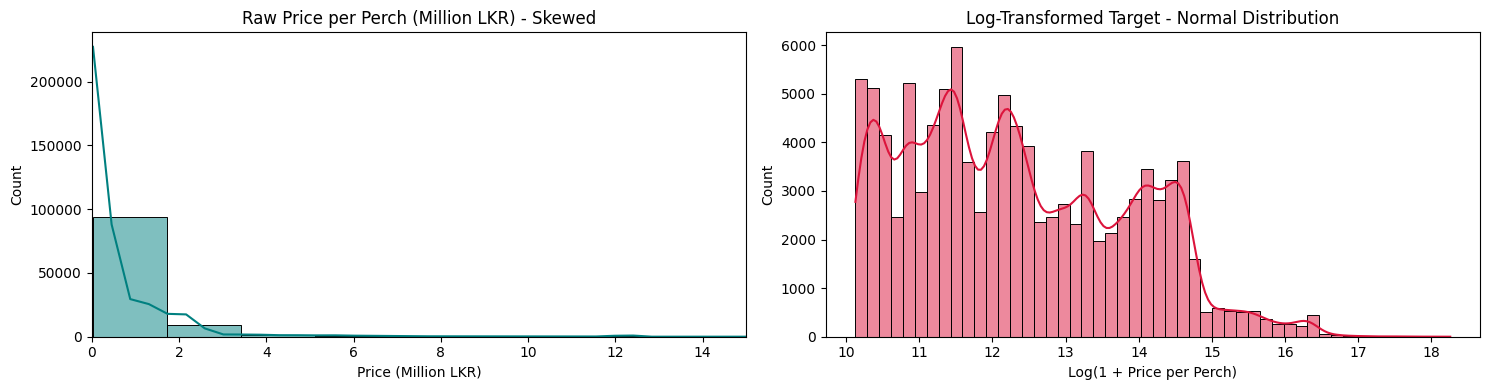

In [ ]:
df_clean['log_price_per_perch'] = np.log1p(df_clean['price_per_perch'])

fig, axes = plt.subplots(1, 2, figsize=(15, 4))

# Raw Skewed Distribution
sns.histplot(df_clean['price_per_perch'] / 1e6, bins=50, kde=True, ax=axes[0], color='teal')
axes[0].set_title('Raw Price per Perch (Million LKR) - Skewed')
axes[0].set_xlabel('Price (Million LKR)')
axes[0].set_xlim(0, 15)

# Log Transformed Gaussian Distribution
sns.histplot(df_clean['log_price_per_perch'], bins=50, kde=True, ax=axes[1], color='crimson')
axes[1].set_title('Log-Transformed Target - Normal Distribution')
axes[1].set_xlabel('Log(1 + Price per Perch)')

plt.tight_layout()
plt.show()

In [ ]:
scaler = RobustScaler()
df_clean['perches_scaled'] = scaler.fit_transform(df_clean[['perches']])

# Categorical binary flags
df_clean['is_colombo'] = (df_clean['district'] == 'Colombo').astype(int)
df_clean['is_bare_land'] = (df_clean['property_type'] == 'Bare Land').astype(int)

print("Standardized numerical features and encoded flags.")
display(df_clean.head(3))

Standardized numerical features and encoded flags.


,district,location,property_type,land_type,perches,price_per_perch,dataset_source,log_price_per_perch,perches_scaled,is_colombo,is_bare_land
0,Colombo,battaramulla,Bare Land,"Commercial, Residential",12.0,3800000.0,colombo_land_detailed,15.150512,0.250,1,1
1,Colombo,nawala,Bare Land,"Commercial, Residential",22.0,6500000.0,colombo_land_detailed,15.687313,1.500,1,1
2,Colombo,mount lavinia,Bare Land,Residential,23.0,2600000.0,colombo_land_detailed,14.771022,1.625,1,1


In [ ]:
from google.colab import files

output_csv = 'datasets_cleaned.csv'
df_clean.to_csv(output_csv, index=False)

print("=" * 60)
print(f"Master Dataset Saved: {output_csv}")
print(f"Total Valid Records: {len(df_clean):,d} rows by {df_clean.shape[1]} columns.")
print("=" * 60)

# Download from Colab
try:
    files.download(output_csv)
    print("Downloading")
except Exception as e:
    print(f"File written to disk: {e}")

Master Dataset Saved: datasets_cleaned.csv
Total Valid Records: 106,452 rows by 11 columns.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloading
